In [1]:
import pandas as pd
import numpy as np
import sys
import os

PROJECT_PATH = os.path.abspath("..")

if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

DATA_PATH = "../data/customer_churn_dataset.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")

Dataset shape: (5000, 13)


In [2]:
df.columns.tolist()

['customer_id',
 'age',
 'gender',
 'subscription_type',
 'monthly_fee',
 'tenure_months',
 'monthly_usage_hours',
 'support_tickets',
 'payment_failures',
 'discount',
 'satisfaction_score',
 'competitor_usage',
 'churn']

In [3]:
X = df.drop(columns=["churn", "customer_id"])
y = df["churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5000, 11)
y shape: (5000,)


In [4]:
X.dtypes

age                      int64
gender                  object
subscription_type       object
monthly_fee            float64
tenure_months            int64
monthly_usage_hours    float64
support_tickets          int64
payment_failures         int64
discount               float64
satisfaction_score       int64
competitor_usage         int64
dtype: object

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining churn rate:", y_train.mean())
print("Test churn rate:", y_test.mean())

Training set: (4000, 11)
Test set: (1000, 11)

Training churn rate: 0.37925
Test churn rate: 0.379


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = [
    "gender",
    "subscription_type"
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [8]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [9]:
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

evaluation = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

evaluation

{'Accuracy': 0.797,
 'Precision': 0.7666666666666667,
 'Recall': 0.6675461741424802,
 'F1 Score': 0.7136812411847673,
 'ROC-AUC': 0.8661151687422193}

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[544  77]
 [126 253]]


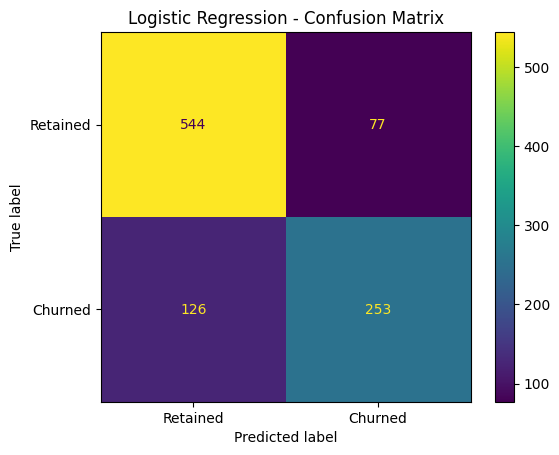

In [12]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Retained", "Churned"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [13]:
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = logistic_model.named_steps["classifier"].coef_[0]

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

feature_importance["odds_ratio"] = np.exp(
    feature_importance["coefficient"]
)

feature_importance.sort_values(
    "odds_ratio",
    ascending=False
)

,feature,coefficient,odds_ratio
4,num__support_tickets,0.853873,2.348726
5,num__payment_failures,0.566447,1.761995
8,num__competitor_usage,0.380314,1.462744
1,num__monthly_fee,0.360981,1.434737
11,cat__subscription_type_Premium,-0.013960,0.986137
12,cat__subscription_type_Standard,-0.065415,0.936678
9,cat__gender_Male,-0.066758,0.935422
0,num__age,-0.070108,0.932293
6,num__discount,-0.118817,0.887970
10,cat__gender_Other,-0.267160,0.765551


In [14]:
import statsmodels.api as sm

In [15]:
X_stats = pd.get_dummies(
    X,
    columns=["gender", "subscription_type"],
    drop_first=True
)

X_stats = X_stats.astype(float)

X_stats = sm.add_constant(X_stats)

print(X_stats.shape)
print(X_stats.dtypes)

(5000, 14)
const                         float64
age                           float64
monthly_fee                   float64
tenure_months                 float64
monthly_usage_hours           float64
support_tickets               float64
payment_failures              float64
discount                      float64
satisfaction_score            float64
competitor_usage              float64
gender_Male                   float64
gender_Other                  float64
subscription_type_Premium     float64
subscription_type_Standard    float64
dtype: object


In [16]:
logit_model = sm.Logit(y, X_stats)

logit_result = logit_model.fit()

print(logit_result.summary())

Optimization terminated successfully.
         Current function value: 0.438765
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  churn   No. Observations:                 5000
Model:                          Logit   Df Residuals:                     4986
Method:                           MLE   Df Model:                           13
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.3389
Time:                        11:57:19   Log-Likelihood:                -2193.8
converged:                       True   LL-Null:                       -3318.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const                          2.8222      0.331      8.529      0.000      

In [17]:
odds_ratio_table = pd.DataFrame({
    "feature": logit_result.params.index,
    "coefficient": logit_result.params.values,
    "p_value": logit_result.pvalues.values,
    "odds_ratio": np.exp(logit_result.params.values),
    "CI_lower": np.exp(logit_result.conf_int()[0].values),
    "CI_upper": np.exp(logit_result.conf_int()[1].values)
})

odds_ratio_table.sort_values("p_value")

,feature,coefficient,p_value,odds_ratio,CI_lower,CI_upper
5,support_tickets,0.637040,1.291003e-69,1.890876,1.761640,2.029592
3,tenure_months,-0.050447,7.385162e-56,0.950804,0.944853,0.956794
8,satisfaction_score,-0.926014,2.518722e-51,0.396129,0.351185,0.446826
4,monthly_usage_hours,-0.037810,5.033870e-45,0.962895,0.957841,0.967977
6,payment_failures,0.731674,1.080952e-41,2.078558,1.869482,2.311016
9,competitor_usage,0.876914,3.752620e-25,2.403472,2.036070,2.837170
0,const,2.822235,1.480226e-17,16.814387,8.790410,32.162735
7,discount,-1.570041,1.770425e-03,0.208037,0.077742,0.556701
2,monthly_fee,0.009465,1.656639e-01,1.009510,0.996091,1.023109
11,gender_Other,-0.289382,1.938117e-01,0.748726,0.483898,1.158488
